# Spherical harmonics notebook

When we separate Laplace's equation in spherical coordinates **without** azimuthal symmetry, the angular part of the solution depends on both $\theta$ and $\phi$. The $\theta$ part satisfies the associated Legendre equation:

$$
(1-x^2)y'' - 2xy' + \left[l(l+1) - \frac{m^2}{1-x^2}\right]y = 0
$$

with $x = \cos\theta$. The solutions that stay finite at $x = \pm 1$ are the associated Legendre functions of the first kind, $P_l^m(x)$, where $l = 0, 1, 2, \ldots$ and $m = 0, 1, \ldots, l$.

Combining $P_l^m(\cos\theta)$ with the $\phi$ part $e^{im\phi}$ gives the spherical harmonics:

$$
Y_l^m(\theta, \phi) = N_{lm}\,P_l^m(\cos\theta)\,e^{im\phi}
$$

where $N_{lm}$ is a normalization constant.

In this notebook, we use $l = 0, 1, 2, 3$ and $m = 0, 1, \ldots, l$.

## Associated Legendre functions of the first kind

The associated Legendre functions are built from the Legendre polynomials:

$$
P_l^m(x) = (-1)^m(1-x^2)^{m/2}\frac{d^m}{dx^m}P_l(x)
$$

Some examples:

$$
P_1^1(x) = -(1-x^2)^{1/2}, \qquad P_2^1(x) = -3x(1-x^2)^{1/2}, \qquad P_2^2(x) = 3(1-x^2)
$$

Properties of associated Legendre functions of the first kind:
- $P_l^0(x) = P_l(x)$, the ordinary Legendre polynomials.
- $P_l^m(x) = 0$ if $m > l$.
- For $m > 0$, $P_l^m(\pm 1) = 0$.
- When $m$ is odd, $P_l^m(x)$ is **not** a polynomial because of the $(1-x^2)^{1/2}$ factor.
- $P_l^m(x)$ has $l - m$ zeros between $-1$ and $1$ (not counting the endpoints).

**Note:** The factor $(-1)^m$ is called the Condon-Shortley phase. Some textbooks leave it out. SciPy includes it.

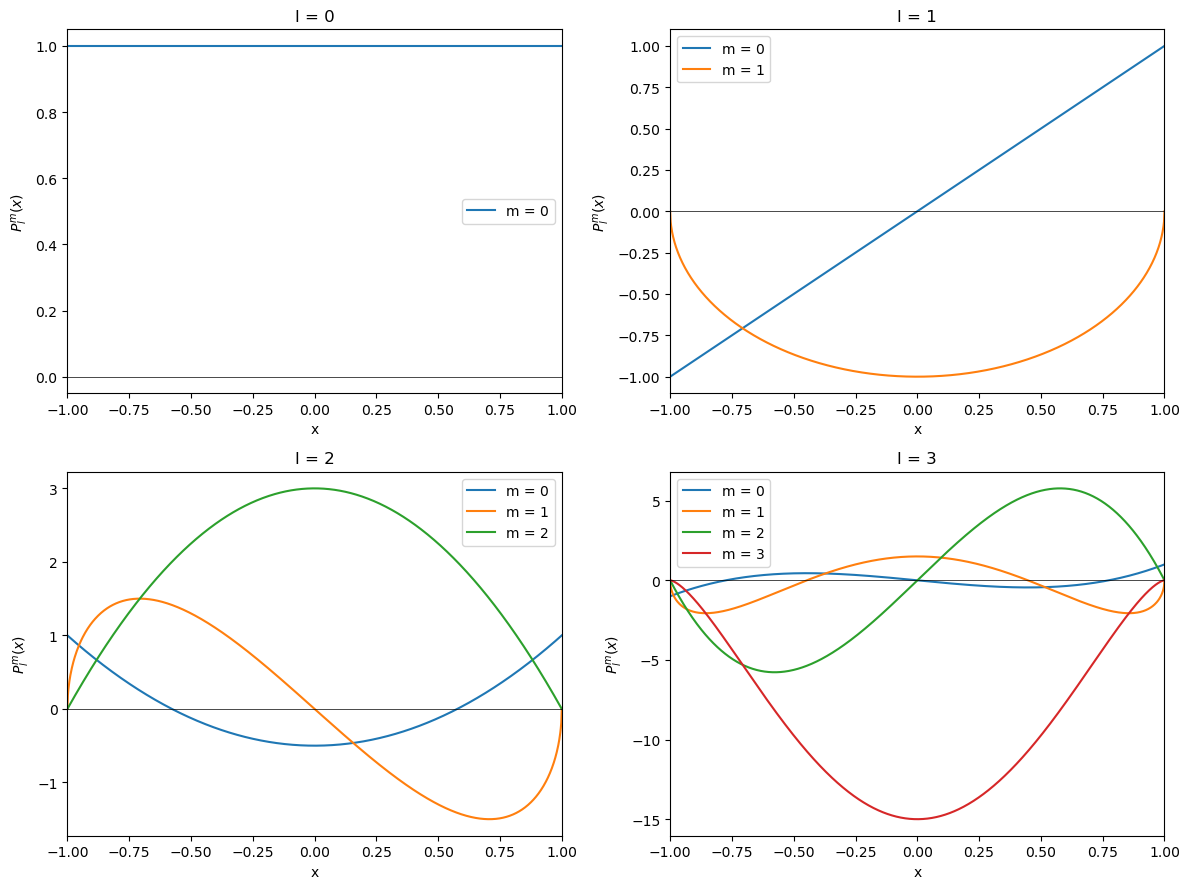

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

# Constants
l_values = [0, 1, 2, 3]

x = np.linspace(-1, 1, num = 1000)

fig, axes = plt.subplots(2, 2, figsize=(12,9))
axes = axes.flatten()
for l in l_values:
    ax = axes[l]
    for m in range(l+1):
        ax.plot(x, sp.special.lpmv(m, l, x), label=f"m = {m}")
    ax.axhline(0, color='k', linewidth=0.5)
    ax.legend(loc="best")
    ax.set_title(f"l = {l}")
    ax.set_ylabel(r"$P_l^m(x)$")
    ax.set_xlabel("x")
    ax.set_xlim(-1, 1)

plt.tight_layout()
plt.show()


## Associated Legendre functions as a function of $\cos\theta$

Now we use $x = \cos\theta$, where $\theta$ is the polar angle measured from the vertical axis. For each angle $\theta$, we draw a point at distance $|P_l^m(\cos\theta)|$ from the origin in that direction:

$$
x_{\text{plot}} = |P_l^m(\cos\theta)|\sin\theta, \qquad y_{\text{plot}} = |P_l^m(\cos\theta)|\cos\theta
$$

This is a polar plot. The vertical axis plays the role of the $z$ axis in 3D. We let $\theta$ go all the way around from $0$ to $2\pi$ so the plot shows both sides of the vertical axis. Red lobes are where $P_l^m(\cos\theta) > 0$ and blue lobes are where $P_l^m(\cos\theta) < 0$.

Notice that:
- The number of lobes from top to bottom is $l - m + 1$.
- For $m > 0$, the function is zero along the vertical axis ($\theta = 0$ and $\theta = \pi$).
- Each plot has its own scale, since $P_l^m$ gets larger as $m$ increases.

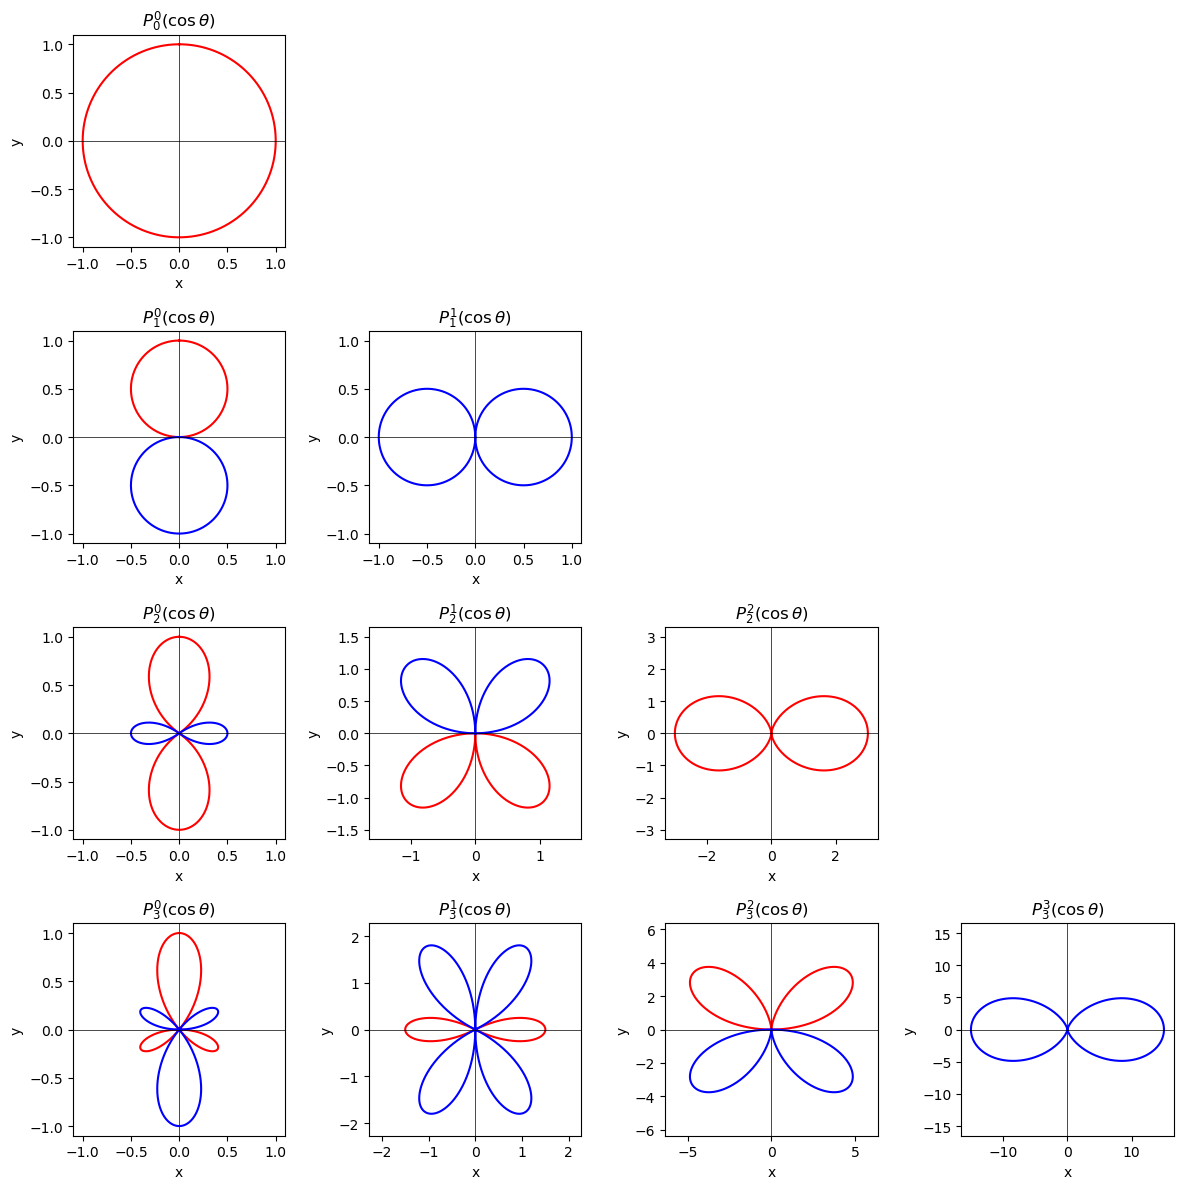

In [2]:
theta = np.linspace(0, 2*np.pi, num = 2000)

fig, axes = plt.subplots(4, 4, figsize=(12,12))
for l in l_values:
    for m in range(4):
        ax = axes[l, m]
        if m > l:
            ax.axis("off")
            continue

        P = sp.special.lpmv(m, l, np.cos(theta))
        r = np.abs(P)
        xp = r*np.sin(theta)
        yp = r*np.cos(theta)

        # Positive lobes in red, negative lobes in blue
        ax.plot(np.where(P >= 0, xp, np.nan), np.where(P >= 0, yp, np.nan), 'r')
        ax.plot(np.where(P <= 0, xp, np.nan), np.where(P <= 0, yp, np.nan), 'b')
        ax.axhline(0, color='k', linewidth=0.5)
        ax.axvline(0, color='k', linewidth=0.5)

        rmax = 1.1*r.max()
        ax.set_xlim(-rmax, rmax)
        ax.set_ylim(-rmax, rmax)
        ax.set_aspect("equal")
        ax.set_title(fr"$P_{l}^{m}(\cos\theta)$")
        ax.set_xlabel("x")
        ax.set_ylabel("y")

plt.tight_layout()
plt.show()


## Spherical harmonics

The spherical harmonics are:

$$
Y_l^m(\theta, \phi) = \sqrt{\frac{2l+1}{4\pi}\frac{(l-m)!}{(l+m)!}}\,P_l^m(\cos\theta)\,e^{im\phi}
$$

They are complex. Using Euler's formula, $e^{im\phi} = \cos(m\phi) + i\sin(m\phi)$, so the real part is:

$$
\text{Re}\left[Y_l^m(\theta, \phi)\right] = N_{lm}\,P_l^m(\cos\theta)\cos(m\phi)
$$

Below, we color a sphere of fixed radius $R = 1$ according to the value of $\text{Re}\left[Y_l^m\right]$ for the same values of $l$ and $m$ as above. Red is positive, blue is negative, and white is zero. Each plot uses its own color scale.

Notice that:
- When $m = 0$, we recover the Legendre polynomials from the previous notebook: the pattern does not depend on $\phi$.
- The zeros come in two types: $l - m$ circles of constant latitude (from $P_l^m(\cos\theta)$) and $m$ great circles through the poles (from $\cos(m\phi)$). In total, there are $l$ nodal lines.
- When $m = l$, all the nodal lines go through the poles.

The imaginary part ($\sin(m\phi)$ instead of $\cos(m\phi)$) looks the same, rotated by $\pi/(2m)$ about the $z$ axis.

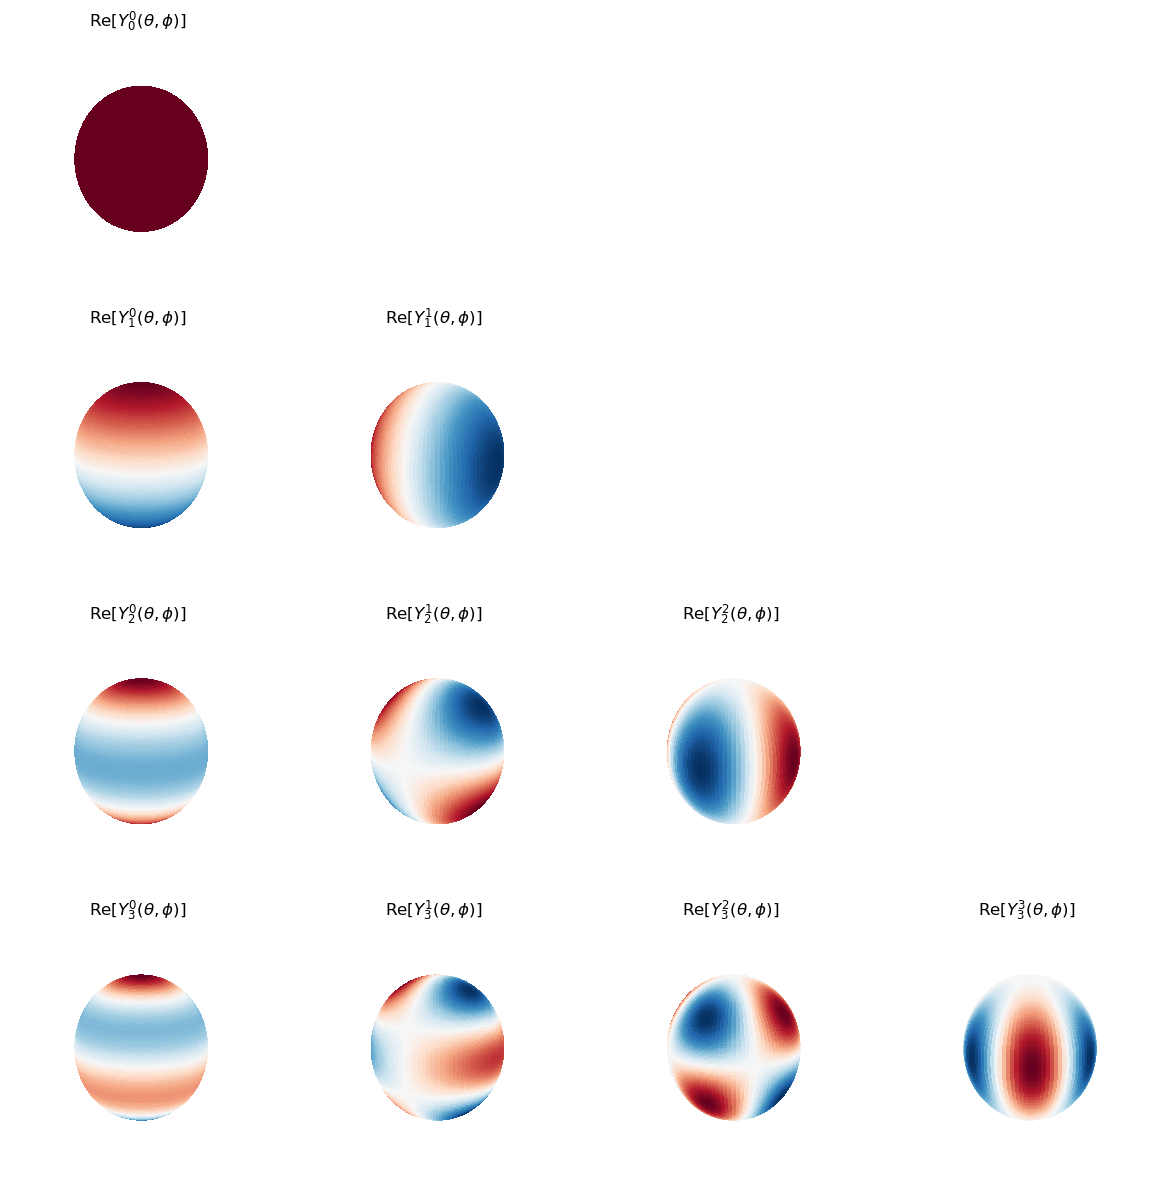

In [3]:
# Constants
R = 1.0
N = 100

# Create theta and phi axis
theta = np.linspace(0, np.pi, N)
phi = np.linspace(0, 2*np.pi, N)
THETA, PHI = np.meshgrid(theta, phi)

# Create x, y, and z axis
X = R*np.sin(THETA)*np.cos(PHI)
Y = R*np.sin(THETA)*np.sin(PHI)
Z = R*np.cos(THETA)

cmap = plt.get_cmap("RdBu_r")

# Create figure
fig = plt.figure(figsize=(12, 12))

for l in l_values:
    for m in range(l+1):
        ax = fig.add_subplot(4, 4, 4*l + m + 1, projection="3d")

        # sph_harm_y(l, m, theta, phi) with theta the polar angle
        Ylm = sp.special.sph_harm_y(l, m, THETA, PHI).real

        # Symmetric color scale for each plot so that white is zero
        vmax = np.abs(Ylm).max()
        norm = plt.Normalize(vmin=-vmax, vmax=vmax)

        ax.plot_surface(X, Y, Z, facecolors=cmap(norm(Ylm)), rstride=1, cstride=1,
                        linewidth=0, antialiased=False, shade=False)

        ax.set_title(fr"Re$[Y_{l}^{m}(\theta,\phi)]$")
        ax.set_box_aspect([1, 1, 1])
        ax.azim = -60
        ax.elev = 15
        ax.set_axis_off()

plt.tight_layout()
plt.show()
